# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Cuarta Dimensión

* Ezequiel Espejo LU 483/22
* Melanie Espinoza LU 1635/23
* Jimena Jofré LU 696/23
* Alison Herrera 814/23

In [ ]:
from alc import *
import numpy as np
import cv2


### Ejercicio 1 - DLT ecuaciones formales

### Ejercicio 1.a – Rango de Q y cantidad mínima de puntos

A partir de la ecuación (6) del enunciado, tenemos el sistema
homogéneo:

$$
Qm = 0
$$

donde $Q \in \mathbb{R}^{2n \times 12}$ y
$m \in \mathbb{R}^{12}$ contiene los coeficientes de
la matriz de proyección $M$.

Queremos determinar qué rango debe tener $Q$ para garantizar
una solución no nula única, salvo un factor de escala.

**1. Condición sobre el rango de Q**

Como el sistema es homogéneo, siempre admite la solución
trivial $m=0$. Sin embargo, buscamos una solución no nula
que represente una matriz de proyección.

Por el teorema de rango-nulidad:

$$
\operatorname{rg}(Q) + \dim(\ker(Q)) = 12
$$

Para que exista una única solución no nula salvo un factor
de escala, necesitamos que el núcleo de $Q$ tenga dimensión 1:

$$
\dim(\ker(Q)) = 1
$$

Esto significa que todas las soluciones pertenecen al
subespacio generado por un mismo vector no nulo $m_0$:

$$
m = \alpha m_0, \qquad \alpha \neq 0
$$

Reemplazando en el teorema de rango-nulidad:

$$
\operatorname{rg}(Q) + 1 = 12
$$

Por lo tanto:

$$
\boxed{\operatorname{rg}(Q)=11}
$$

De esta manera, el sistema tiene un núcleo unidimensional,
lo que garantiza que la matriz de proyección queda determinada
salvo un factor de escala.

**2. Cantidad mínima de puntos**

Cada correspondencia entre un punto tridimensional
$(U_i,V_i,W_i)$ y su proyección $(u_i,v_i)$ aporta dos
ecuaciones lineales al sistema.

Por lo tanto, para $n$ puntos, la matriz $Q$ tiene
$2n$ filas y 12 columnas.

Sabemos que el rango de una matriz está acotado por
su cantidad de filas y columnas:

$$
\operatorname{rg}(Q) \leq \min(2n,12)
$$

Como necesitamos que el rango sea 11:

$$
2n \geq 11
$$

Despejando:

$$
n \geq \frac{11}{2}
$$

Dado que la cantidad de puntos debe ser entera:

$$
\boxed{n_{\min}=6}
$$

Por lo tanto, necesitamos al menos 6 correspondencias
entre puntos 3D y puntos 2D.

**3. Condiciones que deben cumplir los puntos**

Tener 6 puntos es una condición necesaria, pero no
suficiente para garantizar la solución única.

Los puntos deben encontrarse en una configuración
no degenerada, de modo que las ecuaciones aporten
suficiente información independiente.

En particular, los puntos tridimensionales no deben
ser todos coplanares, ya que en ese caso no es posible
determinar una matriz de proyección 3D general de forma única.

Además, deben evitarse otras configuraciones degeneradas
que provoquen dependencias entre las filas de $Q$.

La condición algebraica que garantiza la unicidad es:

$$
\boxed{\operatorname{rg}(Q)=11}
$$

**Conclusión**

Para que el sistema homogéneo $Qm=0$ tenga una solución
no nula única salvo un factor de escala, necesitamos
que el núcleo de $Q$ tenga dimensión 1.

Por el teorema de rango-nulidad, esto equivale a:

$$
\boxed{\operatorname{rg}(Q)=11}
$$

Como cada correspondencia aporta dos ecuaciones, se
requieren al menos 6 puntos en una configuración
no degenerada que permita alcanzar dicho rango.

### Ejercicio 1.b – Resolución del problema de minimización

Buscamos encontrar el vector $m$ que resuelve:

$$
\min_{\|m\|_2=1}m^TQ^TQm
$$

**1. Propiedades de la matriz $Q^TQ$**

Definimos $A=Q^TQ$. Primero, observamos que $A$ es simétrica, ya que:

$$
A^T=(Q^TQ)^T=Q^T(Q^T)^T=Q^TQ=A
$$

Además, $A$ es semidefinida positiva porque, para cualquier vector $x\in\mathbb{R}^{12}$:

$$
x^TAx=x^TQ^TQx=(Qx)^T(Qx)=\|Qx\|_2^2\geq0
$$

Por lo tanto, todos los autovalores de $A$ son reales y no negativos.

**2. Aplicación del teorema espectral**

Como $A$ es simétrica, por el teorema espectral existe una base ortonormal de autovectores $v_1,\ldots,v_{12}$, asociados a los autovalores:

$$
\lambda_1\leq\lambda_2\leq\cdots\leq\lambda_{12}
$$

Podemos expresar cualquier vector $m$ como:

$$
m=\sum_{i=1}^{12}c_iv_i
$$

Como los autovectores son ortonormales y $\|m\|_2=1$, se cumple:

$$
\sum_{i=1}^{12}c_i^2=1
$$

**3. Determinación del mínimo**

Reemplazando la expresión de $m$ en la función que queremos minimizar y utilizando que $Av_i=\lambda_iv_i$ y $v_i^Tv_j=0$ para $i\neq j$, obtenemos:

$$
m^TAm=\sum_{i=1}^{12}\lambda_ic_i^2
$$

Como $\lambda_1$ es el menor autovalor y $c_i^2\geq0$:

$$
m^TAm=\sum_{i=1}^{12}\lambda_ic_i^2
\geq\lambda_1\sum_{i=1}^{12}c_i^2
=\lambda_1
$$

Esta cota se alcanza tomando $m=v_1$, ya que $v_1$ es un autovector unitario asociado a $\lambda_1$.

Por lo tanto:

$$
\boxed{
\min_{\|m\|_2=1}m^TQ^TQm
=\lambda_{\min}(Q^TQ)
}
$$

**Conclusión**

El vector $m$ que resuelve el problema de minimización es un autovector unitario de $Q^TQ$ asociado a su menor autovalor:

$$
\boxed{Q^TQm=\lambda_{\min}m}
$$


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Para cada par de puntos $p_i$ y $P_i$, construimos una matriz $\hat{Q}$ . Agregamos un 1 al final  cada  $p_i$ en R2 y $P_i$ R3 :

$$\begin{pmatrix}u\\v\\1\end{pmatrix}(U\quad V\quad W\quad 1)=\begin{pmatrix}uU&uV&uW&u\\vU&vV&vW&v\\U&V&W&1\end{pmatrix}$$

Defino una matriz que me permita permutar y cambiar de signo
$$\begin{pmatrix}0&0&1\\-1&0&0\\0&-1&0\end{pmatrix}\quad \hat{Q}=\begin{pmatrix}U&V&W&1\\-uU&-uV&-uW&-u\\-vU&-vV&-vW&-v\end{pmatrix}$$

Defino un transformación lineal $T:\mathbb{R}^{3\times4}\rightarrow\mathbb{R}^{2\times12}$

$$\begin{pmatrix}m_{11}&m_{12}&m_{13}&m_{14}\\m_{21}&m_{22}&m_{23}&m_{24}\\m_{31}&m_{32}&m_{33}&m_{34}\end{pmatrix}=\begin{pmatrix}m_{11}&m_{12}&m_{13}&1&0&0&0&0&m_{21}&m_{22}&m_{23}&m_{24}\\0&0&0&0&m_{11}&m_{12}&m_{13}&1&m_{31}&m_{32}&m_{33}&m_{34}\end{pmatrix}$$

Matriz asociada a $T$

$$[T]=\begin{pmatrix}[T(E_1)]&[T(E_2)]&\cdots&[T(E_{12})]\end{pmatrix}\in\mathbb{R}^{24\times12}$$


Transformamos la matriz $\hat{Q}\in\mathbb{R}^{3\times4}$ en un vector columna $q\in\mathbb{R}^{12\times1}$, conservando sus elementos y ordenándolos por filas.

Multiplico ${T}$ ${q}$ = $$\begin{pmatrix}U_i&V_i&W_i&1&0&0&0&0&-u_iU_i&-u_iV_i&-u_iW_i&-u_i\\0&0&0&0&U_i&V_i&W_i&1&-v_iU_i&-v_iV_i&-v_iW_i&-v_i\end{pmatrix}$$

### b) Obtención de la matriz de proyección

En este ejercicio buscamos obtener la matriz de proyección $M$ a partir de la matriz $Q$ construida mediante el método DLT.

Como demostramos en el **Ejercicio 1.b**, el vector $m$ que minimiza:

$$
\min_{\|m\|_2=1}m^TQ^TQm
$$

es un autovector unitario asociado al menor autovalor de $Q^TQ$.

Por lo tanto, primero calculamos:

$$
A=Q^TQ
$$

Luego, obtenemos el autovector $m$ correspondiente al menor autovalor de $A$:

$$
Am=\lambda_{\min}m
$$

Una vez obtenido $m\in\mathbb{R}^{12}$, reorganizamos sus componentes para construir la matriz de proyección de dimensión $3\times4$:

$$
M=
\begin{pmatrix}
m_1&m_2&m_3&m_4\\
m_5&m_6&m_7&m_8\\
m_9&m_{10}&m_{11}&m_{12}
\end{pmatrix}
$$


Cabe destacar que $M$ queda determinada salvo un factor de escala no nulo, ya que multiplicarla por un escalar no modifica la proyección representada.

**Correcciones que se hicieron para la reentrega en el codigo:**
Como la matriz de proyección \(M\) está definida salvo un factor de escala, tanto \(M\) como \(-M\) representan la misma proyección. Por este motivo, calculamos el determinante de la submatriz formada por las primeras tres columnas de \(M\). Si este es negativo, multiplicamos \(M\) por \(-1\), garantizando así que dicho determinante sea positivo.

Esta corrección, junto con la utilización de la factorización QR mediante Gram-Schmidt, permite obtener en el ejercicio 2.c una matriz de rotación \(R\) con determinante igual a 1, evitando realizar una corrección adicional de su signo.

**Comentario sobre el codigo**

Utilizamos la factorización QR mediante Gram-Schmidt, ya que los elementos de la diagonal de la matriz triangular se obtienen a partir de normas y, en el caso no singular, son positivos. Esto, junto con la corrección del signo de \(M\) realizada en el inciso anterior, garantiza que la matriz \(R\) represente una rotación y no una reflexión.

### d)Ejercicio 2.d – Restricciones sobre la matriz K

En este ejercicio modificamos la función devolverMatricesCalibracion3d() para permitir dos restricciones sobre la matriz (K):

Igualar focales: hacer que las dos distancias focales sean iguales.

Skew cero: hacer que el parámetro de sesgo sea cero.

Para aplicar estas restricciones, mantenemos la matriz de rotación (R) y ajustamos el vector (t) para conservar el producto (Kt).


### c) Recuperación de las matrices de calibración

Buscamos recuperar la matriz intrínseca $K$, la matriz de rotación $R$
y el vector de traslación $t$, a partir de la matriz de proyección $M$.

Sabemos que:

$$
M = \lambda K[R \mid t]
$$

Primero dividimos $M$ en una matriz $A$ de dimensión $3 \times 3$
y un vector $b$ de dimensión 3:

$$
M = [A \mid b]
$$

Como necesitamos que $K$ sea triangular superior y $R$ ortogonal,
aplicamos la factorización QR a la inversa de $A$:

$$
A^{-1} = Q_1 R_1
$$

Despejando:

$$
A = R_1^{-1}Q_1^T
$$

Por lo tanto, obtenemos las matrices provisionales:

$$
K_0 = R_1^{-1}, \qquad R_0 = Q_1^T
$$

Normalizamos $K_0$ para garantizar que $K_{33}=1$:

$$
c = (K_0)_{33}, \qquad K = \frac{K_0}{c}
$$

Como la matriz de rotación debe tener determinante 1,
definimos:

$$
s = \operatorname{sign}(\det(R_0))
$$

Y calculamos:

$$
R = sR_0
$$

El factor de escala de la proyección es:

$$
\lambda = cs
$$

Finalmente, como $b = \lambda Kt$, despejamos la traslación:

$$
t = \frac{1}{\lambda}K^{-1}b
$$

Reemplazando las expresiones anteriores y simplificando:

$$
t = sR_1b
$$

De esta manera recuperamos las matrices de calibración $K$, $R$
y el vector de traslación $t$.

In [ ]:
### Validación de la calibración 3D (ejercicios 2.a, 2.b y 2.c)
# Cargamos los puntos detectados en 2D y los puntos del mundo en 3D

datos_r2 = np.loadtxt(" calib/3d/detected_corners.txt")

datos_r3 = np.loadtxt(
    " calib/3d/p_W_corners.txt",
    delimiter=","
)

print(datos_r2.shape)
print(datos_r3.shape)

(210, 24)
(12, 3)


In [ ]:
img_1_r2 = datos_r2[0]

Q = obtenerQ3d(img_1_r2, datos_r3)
M = resolverDLT3D(Q)
R, t, K = devolverMatricesCalibracion3d(M)

print("M:\n", M)
print("K:\n", K)
print("R:\n", R)
print("t:\n", t)

M:
 [[ 6.44865251e-02  2.27816081e-02 -1.39906510e-02  8.37825113e-01]
 [ 3.69903760e-03  6.10180389e-02  1.31187329e-02  5.37810998e-01]
 [ 8.83536974e-05  4.47215909e-05  7.79036974e-05  5.11440311e-03]]
K:
 [[ 4.25859870e+02 -1.56335764e-02  3.54418497e+02]
 [ 0.00000000e+00  4.24565311e+02  2.56853351e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
R:
 [[ 0.61821301  0.12921397 -0.77531698]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494016  0.61829534]]
t:
 [-18.16793826 -14.50326832  40.59129012]


In [ ]:
# calcular el error de reproyeccion
errores = np.zeros(len(datos_r3))

for i in range(len(datos_r3)):
    P = agregar_elemento(datos_r3[i])
    p = matriz_por_vector(M, P)

    u = p[0] / p[2]
    v = p[1] / p[2]

    u_real = img_1_r2[2*i]
    v_real = img_1_r2[2*i+1]

    errores[i] = np.sqrt((u-u_real)**2 + (v-v_real)**2)

print("Error medio de reproyección:", np.mean(errores))
print("Error máximo de reproyección:", np.max(errores))

Error medio de reproyección: 0.3313549116443747
Error máximo de reproyección: 0.7454039528978785


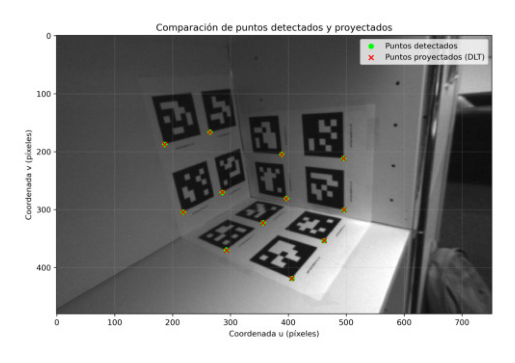

In [ ]:
import matplotlib.pyplot as plt

imagen = plt.imread("recursos_entrega/3d/calibracion_DLT.jpeg")

plt.imshow(imagen)
plt.axis("off")
plt.show()

En el gráfico comparamos los 12 puntos detectados en la primera imagen (verdes) con los puntos calculados usando la matriz \(M\) obtenida por DLT (rojos).

Como los puntos están muy cerca entre sí, podemos ver que la matriz \(M\) aproxima bien sus posiciones. Además, obtuvimos un error promedio de 0,3314 píxeles y un error máximo de 0,7454 píxeles, lo que indica que los resultados son bastante precisos.

In [ ]:
# Otros test sobre R
tol = 1e-6

# Verificamos que R sea ortogonal
assert np.all(np.abs(matriz_x_matriz(R, transpuesta(R))
                     - np.eye(3)) < tol)

# Verificamos que su determinante sea 1
assert np.abs(determinante3x3(R) - 1) < tol

print("R es una matriz de rotación válida")

R es una matriz de rotación válida


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


- ¿Qué rango debe tener $Q\in\mathbb{R}^{2n\times9}$ para asegurar una solución única de $H$, a menos de un factor de escala?

**Por teorema Rango-nulidad**

Sea $M$ una matriz de dimensión $m\times n$, con $n$ columnas. Entonces:

$$\operatorname{rango}(M)+\dim(\operatorname{Nucleo}(M))=n$$

Sea $Q\in\mathbb{R}^{2n\times9}$.

Como queremos una solución única para $Qx=0$, salvo un factor de escala, necesitamos que:

$$\dim(\operatorname{Nucleo}(Q))=1$$

Por lo tanto:

$$\operatorname{rango}(Q)=9-\dim(\operatorname{Nucleo}(Q))=9-1=8$$

Dado que $Q\in\mathbb{R}^{2n\times9}$, para obtener una solución no nula única salvo escala necesitamos que $\operatorname{rango}{Q}=8$.

Como cada correspondencia entre un punto del plano real y su proyección en la imagen aporta dos ecuaciones, necesitamos como mínimo (n=4) puntos.

Estos puntos deben encontrarse en una pose no degenerada. Esto quiere decir que no haya 3 puntos alineados. De manera que las ecuaciones sean suficientemente independientes y la matriz (Q) alcance rango 8.



a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

Para obtener los puntos de las imagenes usamos estas funciones para crear un txt con la misma estructura que el archivo detected_corners.txt

In [ ]:
def obtener_imgPts(ruta_imagen):
    """Detecta las 77 esquinas internas y devuelve sus coordenadas (u,v)."""
    imagen = cv2.imread(str(ruta_imagen))
    if imagen is None:
        raise FileNotFoundError(f"No se pudo leer: {ruta_imagen}")
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    encontrado, esquinas = cv2.findChessboardCorners(gris, (11, 7))
    if not encontrado:
        raise ValueError(f"No se detectaron las esquinas: {ruta_imagen.name}")
    criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    esquinas = cv2.cornerSubPix(gris, esquinas, (11, 11), (-1, -1), criterio)
    return esquinas.reshape(77, 2)

def guardar_imagen_puntos(ruta_imagen, imgPts, carpeta_salida):
    """Guarda la imagen con las esquinas detectadas y numeradas."""
    imagen = cv2.imread(str(ruta_imagen))
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
    alto, ancho = imagen.shape[:2]
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(imagen)
    ax.scatter(imgPts[:, 0], imgPts[:, 1], color="red", s=12)
    for i in range(len(imgPts)):
        ax.text(imgPts[i, 0] + 3, imgPts[i, 1] - 5, str(i), color="blue", fontsize=6)
    ax.set_xlim(0, ancho)
    ax.set_ylim(alto, 0)
    ax.set_title(ruta_imagen.name)
    plt.tight_layout()
    plt.savefig(carpeta_salida / ruta_imagen.name, dpi=180)
    plt.close(fig)

def procesar_imagenes(ruta_carpeta):
    """Procesa las 20 imágenes, genera un TXT y guarda las imágenes numeradas."""
    carpeta = Path(ruta_carpeta)
    if not carpeta.is_dir():
        raise FileNotFoundError(f"No existe la carpeta: {carpeta}")
    carpeta_salida = carpeta / "puntos_detectados"
    carpeta_salida.mkdir(exist_ok=True)
    ruta_txt = carpeta / "detected_corners_2d.txt"
    datos = []
    errores = []
    for numero in range(1, 21):
        ruta_imagen = carpeta / f"Im_R_{numero}.png"
        try:
            imgPts = obtener_imgPts(ruta_imagen)
            guardar_imagen_puntos(ruta_imagen, imgPts, carpeta_salida)
            datos.append(imgPts.reshape(-1))
            print(f"Imagen {numero}: OK - 77 puntos")
        except (FileNotFoundError, ValueError, cv2.error) as error:
            errores.append((numero, str(error)))
            print(f"Imagen {numero}: ERROR - {error}")
    if errores:
        print("No se generó el TXT porque hubo errores de detección.")
        return
    matriz_datos = np.array(datos)
    np.savetxt(ruta_txt, matriz_datos, fmt="%.6f", delimiter=",")
    print("Procesamiento finalizado")
    print("Dimensión:", matriz_datos.shape)
    print("TXT:", ruta_txt)
    print("Imágenes:", carpeta_salida)


In [ ]:
detected_corners_2d='recursos_entrega/coplanar/detected_corners_2d.txt'
datos_pixels=np.loadtxt(detected_corners_2d,delimiter=',')
print(f'Cantidad de imagenes : {len(datos_pixels)}')

Cantidad de imagenes : 20


Los datos U V los contruimos con la función construir_objPts.

Los puntos u v lso tomamos del TXT 'detected_corners_2d'

Obtenemos la matriz K y obtenenmos R y t para la imagen 1.


In [ ]:
datos_puntos_r2=construir_objPts() #construyo los puntos
lista_H=[]
for x in range(0,len(datos_pixels),1):
    Q=obtenerQ2d(datos_pixels[x],datos_puntos_r2)
    H=resolverQhb(Q)
    lista_H.append(H)

A=armarA(lista_H)
K=calcularMatrizK2D(A)
# Pose para las imagen 1
R1,t1=obtenerPose2D(lista_H[0],K)
R20,t20=obtenerPose2D(lista_H[19],K)

print('K:\n')
print(f'{K}\n')
print('R para la imagen 1:\n')
print(f'{R1}\n')
print('t para la imagen 1:\n')
print(f'{t1}\n')
print('R para la imagen 20:\n')
print(f'{R20}\n')
print('t para la imagen 20:\n')
print(f'{t20}\n')



K:

[[745.22306116  -1.00241412 519.50204049]
 [  0.         756.52766588 298.48824344]
 [  0.           0.           1.        ]]

R para la imagen 1:

[[ 0.99954339 -0.01184365 -0.02779815]
 [ 0.01206969  0.99989533  0.00797815]
 [ 0.02770075 -0.00831002  0.99958172]]

t para la imagen 1:

[-108.62062276 -141.27649292  550.35908642]

R para la imagen 20:

[[ 0.98991289  0.02672055 -0.13913478]
 [-0.03880766  0.99563358 -0.08489842]
 [ 0.13625873  0.08944153  0.98662747]]

t para la imagen 20:

[ -83.22847992 -146.30289165  489.26887519]



Calculamos H y K con las funciones de OpenCV

In [ ]:
# 1. Construcción de puntos físicos
puntos_objeto = construir_objPts().astype(np.float64)

# 2. Homografías con OpenCV
lista_H_cv = []
for imagen in datos_pixels:
    puntos_imagen = imagen.reshape(77, 2).astype(np.float64)
    H_cv, _ = cv2.findHomography(puntos_objeto, puntos_imagen, method=0)
    lista_H_cv.append(H_cv)

# 3. Comparación de homografías
H_propia = lista_H[0] / lista_H[0][2, 2]
H_cv = lista_H_cv[0] / lista_H_cv[0][2, 2]
print("H_propia - H_cv:")
print(np.round(H_propia - H_cv, 6))

# 4. Preparación de puntos para calibrateCamera
puntos_3d = np.zeros((77, 3), dtype=np.float32)
puntos_3d[:, :2] = puntos_objeto
objectPoints = [puntos_3d.copy() for _ in range(len(datos_pixels))]
imagePoints = [imagen.reshape(77, 2).astype(np.float32) for imagen in datos_pixels]

# 5. Calibración con OpenCV
ancho, alto = 1024, 576
error, K_cv, dist, rvecs, tvecs = cv2.calibrateCamera(objectPoints, imagePoints, (ancho, alto), None, None)

# 6. Comparación
print("\nK propia:")
print(K)
print("\nK OpenCV:")
print(K_cv)
print("\nDiferencia K:")
print(np.round(K - K_cv, 6))


H_propia - H_cv:
[[-0.     -0.      0.0019]
 [-0.     -0.      0.0009]
 [-0.     -0.      0.    ]]

K propia:
[[745.2231  -1.0024 519.502 ]
 [  0.     756.5277 298.4882]
 [  0.       0.       1.    ]]

K OpenCV:
[[722.0596   0.     513.6959]
 [  0.     732.7347 292.7394]
 [  0.       0.       1.    ]]

Diferencia K:
[[23.1634 -1.0024  5.8062]
 [ 0.     23.793   5.7489]
 [ 0.      0.      0.    ]]


Calculamos K con nuestras funciones a partir de las H calculadas por OpenCV

In [ ]:
A_cv = armarA(lista_H_cv)
K_homografias_cv = calcularMatrizK2D(A_cv)

print("K propia:")
print(K)
print("\nK con homografías OpenCV:")
print(K_homografias_cv)
print("\nDiferencia:")
print(np.round(K - K_homografias_cv, 6))

K propia:
[[745.2231  -1.0024 519.502 ]
 [  0.     756.5277 298.4882]
 [  0.       0.       1.    ]]

K con homografías OpenCV:
[[744.4951  -1.0258 519.7742]
 [  0.     755.7896 298.5663]
 [  0.       0.       1.    ]]

Diferencia:
[[ 0.7279  0.0234 -0.2722]
 [ 0.      0.738  -0.0781]
 [ 0.      0.      0.    ]]


Calculamos R y t para la imagen 1 y comparamos vs los resultados de OpenCV

In [ ]:
H = lista_H[0]
R_propia, t_propia = obtenerPose2D(H, K)
puntos_3d = np.zeros((77, 3), dtype=np.float64)
puntos_3d[:, :2] = datos_puntos_r2
puntos_2d = datos_pixels[0].reshape(77, 2).astype(np.float64)
dist = np.zeros(5)
exito, rvec, t_cv = cv2.solvePnP(puntos_3d, puntos_2d, K, dist, flags=cv2.SOLVEPNP_ITERATIVE)
R_cv, _ = cv2.Rodrigues(rvec)
print("R propia:")
print(R_propia)
print("\nR OpenCV:")
print(R_cv)
print("\nt propia:")
print(t_propia)
print("\nt OpenCV:")
print(t_cv.reshape(3))
print("\nDiferencia R:")
print(np.round(R_propia - R_cv, 6))
print("\nDiferencia t:")
print(np.round(t_propia - t_cv.reshape(3), 6))

R propia:
[[ 0.9995 -0.0126 -0.0278]
 [ 0.0121  0.9995  0.008 ]
 [ 0.0277 -0.0083  0.9992]]

R OpenCV:
[[ 0.9996 -0.0125 -0.0261]
 [ 0.0127  0.9999  0.0057]
 [ 0.026  -0.006   0.9996]]

t propia:
[-108.6206 -141.2765  550.3591]

t OpenCV:
[-108.579  -141.4049  550.5599]

Diferencia R:
[[-0.     -0.     -0.0017]
 [-0.0006 -0.0004  0.0023]
 [ 0.0017 -0.0023 -0.0004]]

Diferencia t:
[-0.0416  0.1284 -0.2008]


# Ejercicio 4 - Ubicación espacial en la cancha de fútbol

Para la foto `gol-enzo.png`, estimar la homografía $H$ del plano de la cancha a la imagen y utilizarla para:

a) Calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol. Para ello, llevar la posición de sus pies de la imagen a la cancha mediante $H^{-1}$.

b) Ubicar espacialmente todos los jugadores argentinos y dibujar un círculo de 1 metro de radio sobre el piso. Para ello, definir el círculo en coordenadas de la cancha y proyectar sus puntos a la imagen mediante $H$.

Para la foto `posibleoffside.jpg`, estimar su propia homografía $H$ y utilizarla para:

c) Trazar una recta paralela a la línea de fondo de la cancha que toque el pie del último defensor (es decir, el penúltimo jugador adversario, contando al arquero) para determinar si los jugadores de blanco estaban en fuera de juego. La recta se define en coordenadas de la cancha y se proyecta a la imagen mediante $H$.

## Planteo

Usamos coordenadas de la cancha: $U$ mide la distancia a la línea de fondo y $V$ el ancho, en metros. En la primera foto, el arco está en $U=0$. Como la cancha es plana, la transformación entre sus puntos y la imagen se modela con una homografía $H$:

$$\lambda \begin{bmatrix}u\\v\\1\end{bmatrix}
= H\begin{bmatrix}U\\V\\1\end{bmatrix}$$

### 1. Transformación proyectiva

Para un punto $(U,V)$, agregamos la coordenada homogénea $1$ y multiplicamos por $H$. Si el resultado es $(a,b,c)$, sus coordenadas en píxeles son:

$$u=\frac{a}{c},\qquad v=\frac{b}{c}.$$

La división por $c$ representa el efecto de la perspectiva.

### 2. Sistema lineal (DLT)

Cada correspondencia entre un punto de la cancha $(U,V)$ y su píxel $(u,v)$ aporta dos ecuaciones:

$$
\begin{bmatrix}
U & V & 1 & 0 & 0 & 0 & -uU & -uV & -u\\
0 & 0 & 0 & U & V & 1 & -vU & -vV & -v
\end{bmatrix}
\begin{bmatrix}
h_{11}\\h_{12}\\\vdots\\h_{33}
\end{bmatrix}
=\begin{bmatrix}0\\0\end{bmatrix}.
$$

Al reunirlas obtenemos $Q\mathbf{h}=0$, donde $Q$ tiene $2n$ filas y 9 columnas. La matriz $H$ tiene 9 entradas, pero está definida salvo un factor de escala, por lo que quedan 8 grados de libertad. Se necesitan al menos 4 puntos en posición general (sin tres alineados) para determinarla.

$H$ transforma coordenadas de la cancha (metros) a la imagen (píxeles); $H^{-1}$ realiza el camino inverso.

### 3. Estimación mediante SVD

Debido al error al marcar los píxeles, en general no existe una solución exacta de $Q\mathbf{h}=0$. Buscamos entonces minimizar $\|Q\mathbf{h}\|^2$ sujeto a $\|\mathbf{h}\|=1$.

Con la descomposición

$$Q=U\Sigma V^T,$$

los valores singulares de $\Sigma$ están ordenados de mayor a menor. El vector singular asociado al menor valor singular (la última columna de $V$) minimiza el error y se toma como $\mathbf{h}$.

Antes de construir $Q$ normalizamos los puntos mediante la normalización de Hartley; al obtener $H$, deshacemos esa normalización.

### ¿Para qué necesitamos $H$ y $H^{-1}$?

Con la homografía $H$ proyectamos puntos desde el sistema de coordenadas de la cancha (en metros) hacia la imagen (en píxeles), mientras que con su inversa $H^{-1}$ realizamos el camino opuesto: llevamos coordenadas de la imagen (píxeles) al plano real de la cancha (metros).

* **Inciso (a) — Uso de $H^{-1}$ (`gol-enzo.png`):** Llevamos la posición de los pies de Enzo desde los píxeles de la imagen al plano real de la cancha mediante $H^{-1}$ para calcular su distancia en línea recta (en metros) hasta la línea del arco.
* **Inciso (b) — Uso de $H^{-1}$ y $H$ (`gol-enzo.png`):** Primero usamos $H^{-1}$ para obtener las coordenadas reales $(U, V)$ en el césped de todos los jugadores argentinos a partir de sus pies en la foto; luego definimos alrededor de cada uno una circunferencia de $1\text{ m}$ de radio en coordenadas de la cancha y aplicamos $H$ para proyectarla sobre la imagen.
* **Inciso (c) — Uso de $H^{-1}$ y $H$ (`posibleoffside.jpg`):** Con $H^{-1}$ ubicamos en coordenadas de la cancha el pie del último defensor para determinar la coordenada de la línea de *offside*; luego definimos esa recta paralela a la línea de fondo en metros y la proyectamos sobre la foto mediante $H$.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
np.set_printoptions(precision=4, suppress=True)


FOTO_ENZO = 'recursos_entrega/futbol/test-gol-enzo.png'
FOTO_OFF = 'recursos_entrega/futbol/test-fuera-de-juego.png'

def valores_singulares(Q):
    """Valores singulares de Q (de mayor a menor), calculados con nuestra svd_reducida.

    Se usa tol = -1 para conservar también el menor valor singular, asociado
    al vector h que buscamos. Con la tolerancia usual podría descartarse
    cuando es muy pequeño, por ejemplo en datos sin ruido.
    """
    U, S, V = svd_reducida(Q, "max", -1.0)
    return S

# Comprobamos las dimensiones de las fotos usadas para marcar los píxeles.
for ruta, (filas, cols) in [(FOTO_ENZO, (674, 1079)), (FOTO_OFF, (1067, 1541))]:
    f = mpimg.imread(ruta)
    if f.shape[0] == filas and f.shape[1] == cols:
        print("%s: %d x %d, coincide con la usada para medir los píxeles" % (ruta, f.shape[0], f.shape[1]))
    else:
        print("ATENCIÓN: %s mide %d x %d y los píxeles se midieron sobre %d x %d: hay que re-medir" % (ruta, f.shape[0], f.shape[1], filas, cols))

recursos_entrega/futbol/test-gol-enzo.png: 674 x 1079, coincide con la usada para medir los píxeles
recursos_entrega/futbol/test-fuera-de-juego.png: 1067 x 1541, coincide con la usada para medir los píxeles


Antes de trabajar con las fotos, probamos estimar_homografia con una matriz H conocida. Generamos píxeles aplicando esa matriz a puntos de la cancha y luego estimaremos H a partir de las correspondencias. También verificamos la transformación de ida y vuelta mediante H⁻¹.

La prueba usa datos sin ruido, por lo que la matriz recuperada debería coincidir con la propuesta salvo pequeños errores numéricos.

In [ ]:
H_inventada = np.array([[1.2, 0.3, 300.0],
                        [-0.1, 0.8, 200.0],
                        [0.001, 0.002, 1.0]])
metros  = np.array([[0, 0], [10, 0], [10, 5], [0, 5], [5, 2.5], [3, 4], [8, 1]], dtype=float)
pixeles = aplicar_homografia(H_inventada, metros)         # "fotografiamos" los puntos
H_recuperada = estimar_homografia(pixeles, metros)        # Estimamos H a partir de las correspondencias.

print("H inventada:\n", H_inventada)
print("H recuperada:\n", H_recuperada)
print("máxima diferencia: %.2e   (debe ser ~1e-10 o menos)" % np.max(np.abs(H_inventada - H_recuperada)))

# ida y vuelta: metros -> píxeles -> metros con la inversa
vuelta = aplicar_homografia(inversa(H_recuperada), pixeles)
print("ida y vuelta (metros -> píxeles -> metros), error máximo: %.2e" % np.max(np.abs(vuelta - metros)))

H inventada:
 [[  1.2     0.3   300.   ]
 [ -0.1     0.8   200.   ]
 [  0.001   0.002   1.   ]]
H recuperada:
 [[  1.2     0.3   300.   ]
 [ -0.1     0.8   200.   ]
 [  0.001   0.002   1.   ]]
máxima diferencia: 2.31e-13   (debe ser ~1e-10 o menos)
ida y vuelta (metros -> píxeles -> metros), error máximo: 1.15e-13


Con la H inventada el algoritmo recupera la matriz original, así que ya podemos usarlo con los datos reales. Ahora trabajamos con las dos fotos del ejercicio, cada una con su propia H.

## Foto 1: `gol-enzo.png`

Puntos de referencia.
Elegimos 8 puntos con medidas reglamentarias conocidas: las 4 esquinas del área chica (5,5 m × 18,32 m), los 2 puntos donde el arco del área corta la línea del área grande (16,5 m) y los pies de los dos palos (arco de 7,32 m). Se distinguen bien en la foto, están repartidos por la imagen y rodean a los jugadores. Mirando hacia el arco, la izquierda de la imagen es V chico.

Los píxeles (u = columna, v = fila, origen arriba a la izquierda) se marcaron a mano con zoom.

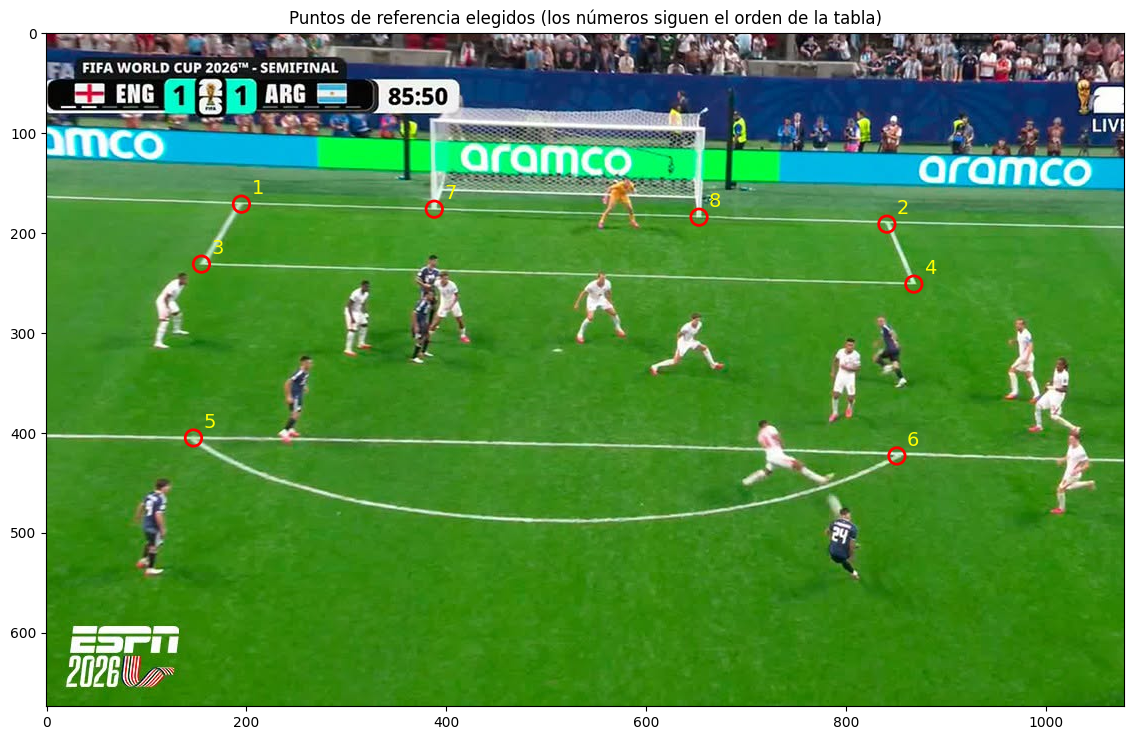

In [ ]:
# Sistema de la cancha (estadio_azteca.png): U = largo (0 a 105 m), V = ancho (0 a 68 m); el arco de la foto está en U = 0.
# Cada fila: (U, V) en metros  <->  (u, v) en píxeles de la foto (u = columna, v = fila, origen arriba a la izquierda).
# Medidos a mano sobre la foto (1079x674) y verificados dibujándolos encima.
referencias_enzo = [
    # U      V      u    v
    (0.0,   24.84, 195, 171),   # esquina del área chica sobre la línea de fondo (izquierda de la imagen)
    (0.0,   43.16, 841, 191),   # esquina del área chica sobre la línea de fondo (derecha)
    (5.5,   24.84, 155, 231),   # esquina del área chica, lado de adelante (izquierda)
    (5.5,   43.16, 868, 251),   # esquina del área chica, lado de adelante (derecha)
    (16.5,  26.69, 147, 405),   # donde el arco del área corta la línea del área grande (izquierda)
    (16.5,  41.31, 851, 423),   # donde el arco del área corta la línea del área grande (derecha)
    (0.0,   30.34, 388, 176),   # pie del palo izquierdo
    (0.0,   37.66, 653, 184),   # pie del palo derecho
]
tabla = np.array(referencias_enzo)
obj_enzo = tabla[:, 0:2]        # metros
img_enzo = tabla[:, 2:4]        # píxeles


foto_enzo = mpimg.imread(FOTO_ENZO)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
for i in range(tabla.shape[0]):
    ax.scatter([tabla[i, 2]], [tabla[i, 3]], s=140, facecolors='none', edgecolors='red', linewidths=2)
    ax.text(tabla[i, 2] + 10, tabla[i, 3] - 10, str(i + 1), color='yellow', fontsize=14)
ax.set_title("Puntos de referencia elegidos (los números siguen el orden de la tabla)")
plt.tight_layout()
plt.show()

Homografía de la foto 1.
Calculamos H con estimar_homografia y la validamos de dos formas: con el error de reproyección y dibujando sobre la foto las líneas de la cancha proyectadas con H.

In [ ]:
H_enzo = estimar_homografia(img_enzo, obj_enzo)
print("H (cancha -> foto), H[2,2]=1:\n", H_enzo)
print("Error de reproyección (RMS): %.2f px" % error_reproyeccion(H_enzo, img_enzo, obj_enzo))

H (cancha -> foto), H[2,2]=1:
 [[  -9.5409   37.3029 -727.9773]
 [   7.7745    1.3329  141.455 ]
 [  -0.0167    0.0011    1.    ]]
Error de reproyección (RMS): 2.01 px


In [ ]:
img_n, _ = normalizar_puntos(img_enzo)    # normalizamos igual que lo hace estimar_homografia
obj_n, _ = normalizar_puntos(obj_enzo)
print("Valores singulares de Q (Enzo):", valores_singulares(armar_Q(img_n, obj_n)))

Valores singulares de Q (Enzo): [5.5857 5.4726 4.1635 3.09   2.7812 2.7201 2.5104 1.172  0.0167]


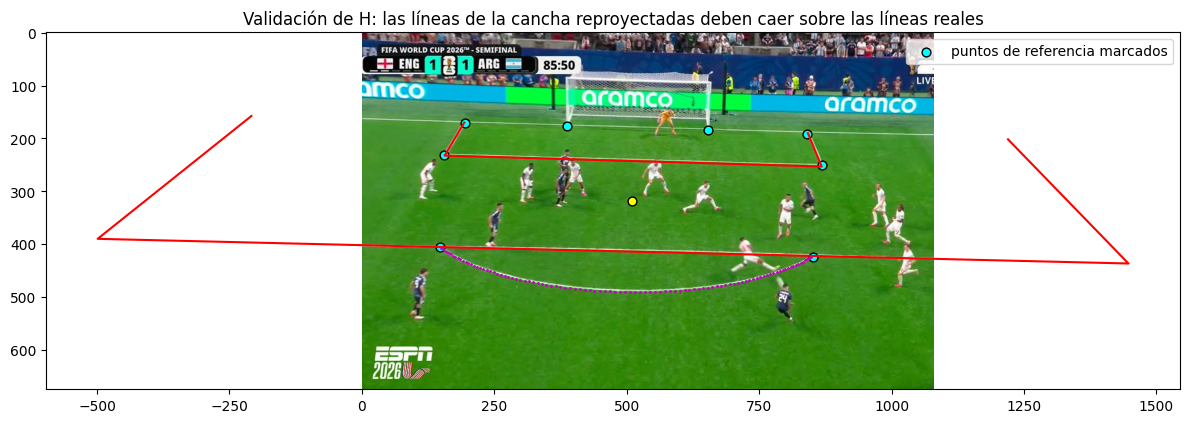

In [ ]:
def dibujar_cancha(H, ax, color='r'):
    """Dibuja sobre la foto las líneas de la cancha (definidas en metros) proyectadas con H, para VALIDAR H."""
    def trazo(puntos):
        p = aplicar_homografia(H, np.array(puntos))
        ax.plot(p[:, 0], p[:, 1], color + '-', linewidth=1.5)
    trazo([[0, 13.84], [16.5, 13.84], [16.5, 54.16], [0, 54.16]])             # área grande
    trazo([[0, 24.84], [5.5, 24.84], [5.5, 43.16], [0, 43.16]])               # área chica
    arco = circulo((11.0, 34.0), 9.15, 100)                                   # arco del área (radio 9,15 m desde el punto penal)
    lista = []
    for i in range(arco.shape[0]):
        if arco[i, 0] >= 16.5:
            lista.append([arco[i, 0], arco[i, 1]])
    p = aplicar_homografia(H, np.array(lista))
    ax.plot(p[:, 0], p[:, 1], 'm.', markersize=2)
    ps = aplicar_homografia(H, np.array([[11.0, 34.0]]))
    ax.scatter(ps[:, 0], ps[:, 1], s=40, c='yellow', edgecolors='k')          # punto penal

foto_enzo = mpimg.imread(FOTO_ENZO)
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
dibujar_cancha(H_enzo, ax)
ax.scatter(img_enzo[:, 0], img_enzo[:, 1], s=40, c='cyan', edgecolors='k', label='puntos de referencia marcados')
ax.set_title("Validación de H: las líneas de la cancha reproyectadas deben caer sobre las líneas reales")
ax.legend()
plt.tight_layout()
plt.show()

Las líneas proyectadas caen sobre las líneas reales de la cancha, así que H está bien estimada.

a) Distancia de Enzo
Marcamos el píxel del pie de apoyo de Enzo (la homografía solo vale para puntos del piso) y lo pasamos a la cancha con H⁻¹. Como el arco está en U = 0, la distancia a la línea del arco es U.

In [ ]:
pie_enzo = np.array([[809.0, 544.0]])                    # píxel del pie de apoyo de Enzo (camiseta 24)
H_inv = inversa(H_enzo)
pos = aplicar_homografia(H_inv, pie_enzo)   # foto -> cancha (en metros)
U, V = pos[0, 0], pos[0, 1]
print("Enzo en la cancha: U = %.2f m (distancia a la línea de fondo), V = %.2f m (a lo ancho)" % (U, V))
print("Distancia perpendicular a la línea del arco: %.2f m" % U)
print("Distancia en línea recta al centro del arco (0, 34): %.2f m" % np.sqrt(U ** 2 + (V - 34.0) ** 2))

Enzo en la cancha: U = 22.15 m (distancia a la línea de fondo), V = 39.80 m (a lo ancho)
Distancia perpendicular a la línea del arco: 22.15 m
Distancia en línea recta al centro del arco (0, 34): 22.90 m


Resultado. Enzo estaba a aproximadamente 22,2 m de la línea del arco (22,9 m del centro del arco). Es un valor razonable: está más lejos que el arco del área (20,15 m).

b) Círculos de 1 m de radio alrededor de los argentinos.
Pasamos a metros los pies de cada jugador argentino con H⁻¹, definimos en metros un círculo de 1 m de radio centrado en cada uno y lo proyectamos a la foto con H. Se ven como elipses porque la perspectiva comprime la dirección de profundidad; dibujar círculos directamente en píxeles estaría mal, porque no representarían 1 m en el piso.

El sexto argentino (arriba, entre dos ingleses) tiene los pies tapados, así que su posición es una estimación.

Posición de cada argentino en la cancha (U, V) en metros:
 [[22.1524 39.8015]
 [16.0734 28.5984]
 [22.3974 27.0554]
 [11.6156 31.0008]
 [12.0382 41.7354]
 [ 9.1481 30.9516]]


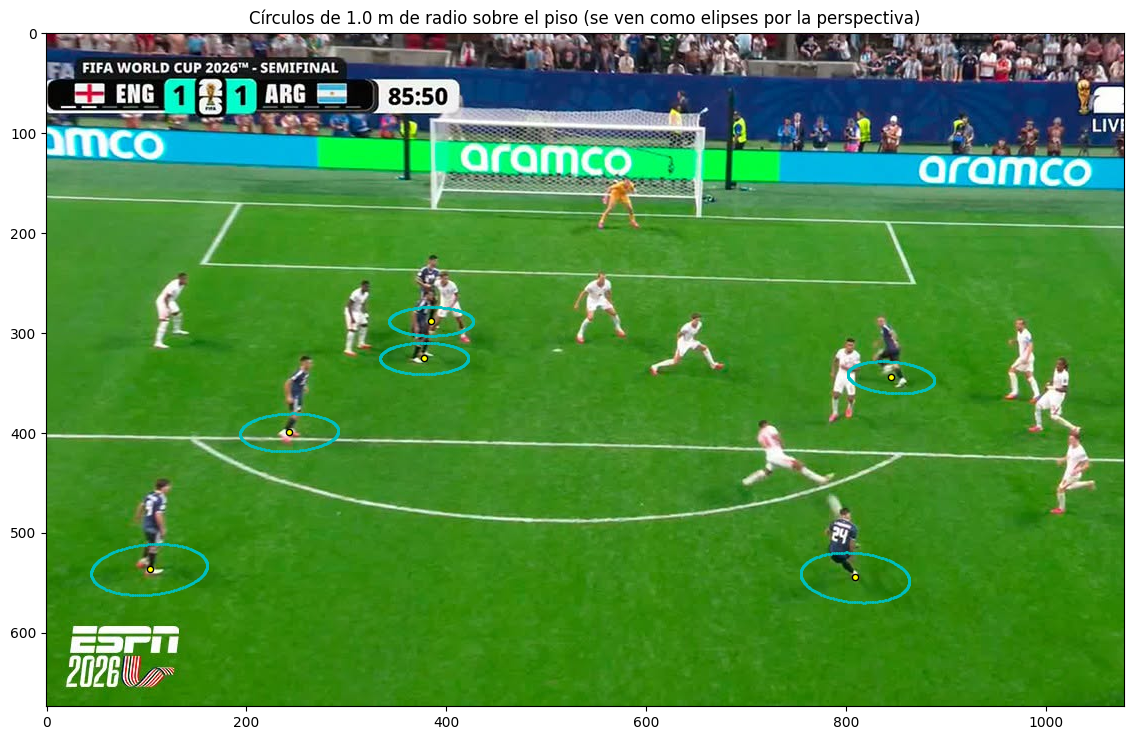

In [ ]:
RADIO = 1.0     # el enunciado pide círculos de 1 metro de radio
pies_argentinos = np.array([      # píxel del pie de cada jugador argentino (camiseta oscura)
    [809.0, 544.0],    # Enzo (24)
    [243.0, 399.0],    # jugador en el borde de la línea del área grande
    [103.0, 536.0],    # jugador abajo a la izquierda
    [378.0, 325.0],    # jugador junto a dos ingleses (centro-izquierda)
    [845.0, 344.0],    # jugador a la derecha, corriendo
    [385.0, 288.0],    # 6.º argentino (jugador entre dos ingleses, arriba): tiene los pies TAPADOS, posición ESTIMADA
])
centros = aplicar_homografia(H_inv, pies_argentinos)     # a metros
print("Posición de cada argentino en la cancha (U, V) en metros:\n", centros)
# Defino y proyeto el gráfico de los círculos
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.imshow(foto_enzo)
for i in range(centros.shape[0]):
    aro = circulo((centros[i, 0], centros[i, 1]), RADIO, 60)   # círculo definido en METROS
    aro_foto = aplicar_homografia(H_enzo, aro)                  # proyectado a la foto
    ax.plot(aro_foto[:, 0], aro_foto[:, 1], 'c.', markersize=2)
ax.scatter(pies_argentinos[:, 0], pies_argentinos[:, 1], s=20, c='yellow', edgecolors='k')
ax.set_title("Círculos de %.1f m de radio sobre el piso (se ven como elipses por la perspectiva)" % RADIO)
plt.tight_layout()
plt.show()

Foto 2: posibleoffside.jpg

### Homografía de la foto 2
La cámara es otra, así que estimamos otra H con puntos de referencia de esta foto. Hay que identificar bien las líneas: la línea casi vertical es la del área grande (16,5 m) y el arco es el arco del área, no el círculo central. Como chequeo independiente, comprobamos dónde cae el punto penal
 y lo comparamos con donde se ve en la foto.

Error de reproyección (RMS): 2.09 px
Chequeo independiente: el punto penal (11, 34) cae en el píxel (1015, 473) y en la foto se ve en ~(1007, 472)


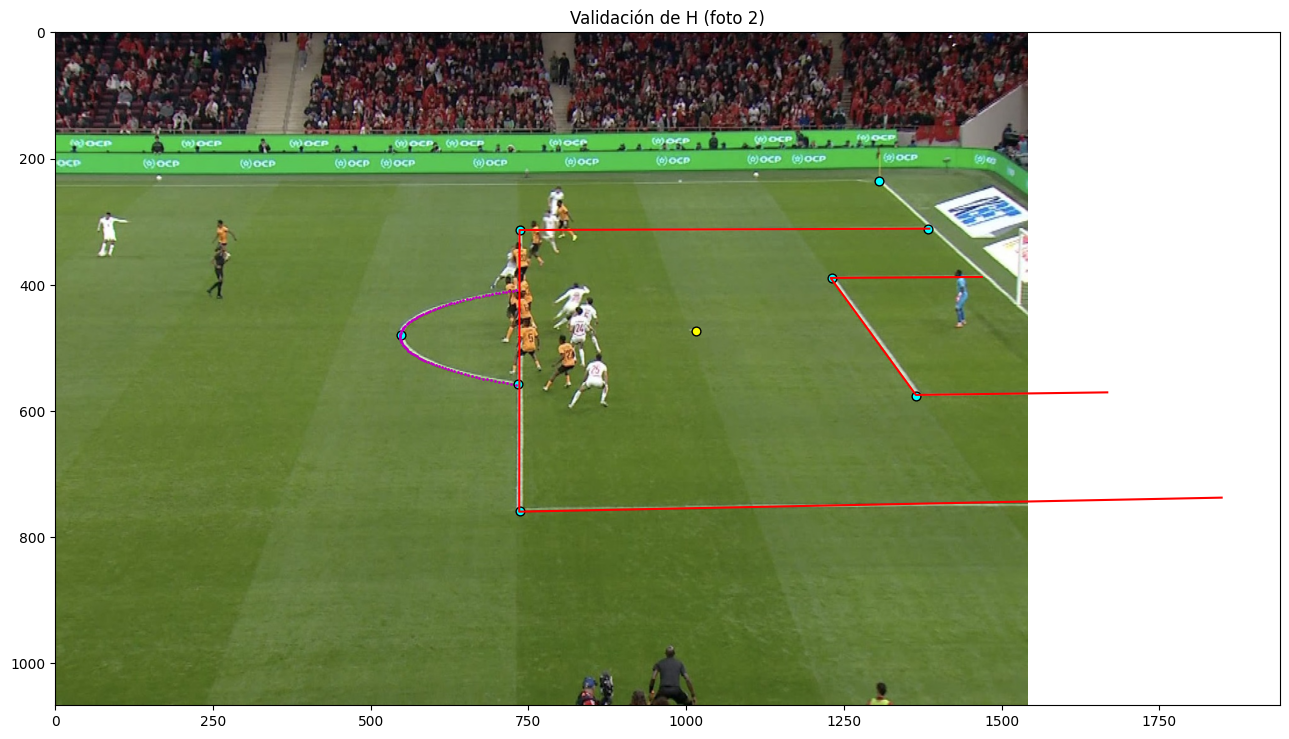

In [ ]:
# Mismo sistema de la cancha: el arco de la foto está en U = 0; la banda más cercana a la cámara es V chico.
# Medidos a mano sobre la foto (1541x1067) y verificados dibujándolos encima.
referencias_off = [
    # U      V      u     v
    (16.5,  13.84,  736,  758),   # esquina cercana del área grande (línea del área con la línea lateral del área)
    (16.5,  54.16,  736,  313),   # esquina lejana del área grande
    (16.5,  26.69,  733,  557),   # donde el arco del área corta la línea del área grande (extremo visible)
    (20.15, 34.0,   548,  480),   # punto más alejado del arco del área (punta de la "D")
    (5.5,   43.16, 1231,  390),   # esquina lejana del área chica (lado de adelante)
    (5.5,   24.84, 1365,  576),   # esquina cercana del área chica (lado de adelante)
    (0.0,   54.16, 1383,  311),   # línea lateral del área grande contra la línea de fondo
    (0.0,   68.0,  1305,  236),   # banderín de córner lejano
]
tabla2 = np.array(referencias_off)
obj_off = tabla2[:, 0:2]
img_off = tabla2[:, 2:4]
H_off = estimar_homografia(img_off, obj_off)
print("Error de reproyección (RMS): %.2f px" % error_reproyeccion(H_off, img_off, obj_off))
penal = aplicar_homografia(H_off, np.array([[11.0, 34.0]]))
print("Chequeo independiente: el punto penal (11, 34) cae en el píxel (%.0f, %.0f) y en la foto se ve en ~(1007, 472)" % (penal[0, 0], penal[0, 1]))

foto_off = mpimg.imread(FOTO_OFF)
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto_off)
dibujar_cancha(H_off, ax)
ax.scatter(img_off[:, 0], img_off[:, 1], s=40, c='cyan', edgecolors='k')
ax.set_title("Validación de H (foto 2)")
plt.tight_layout()
plt.show()

### c) Recta de fuera de juego

Pasamos a metros los pies de los jugadores. El último defensor de campo (el penúltimo adversario, porque el arquero está más cerca de la línea de fondo) es el de menor `U`. La línea de offside es `U = cte`, paralela a la línea de fondo, y se proyecta a la foto con `H`. Un atacante está en posición adelantada si su `U` es menor que la de ese defensor. Consideramos una tolerancia de 15 cm por el error de los clics.

jugador                   U (m)    V (m)
def. lejano (arriba)      14.65    52.01
def. (770,367)            15.72    46.37
def. n.° 5                16.31    28.39
def. n.° 27               15.46    26.40
arquero                    2.48    34.44   (el arquero está más cerca de la línea: es el último adversario)

Último defensor de campo (penúltimo adversario): def. lejano (arriba) a U = 14.65 m

atacante                  U (m) ventaja sobre la línea
atac. (796,468)           15.31      -0.66 m  -> habilitado
atac. (843,592)           14.68      -0.03 m  -> en línea (no concluyente)
atac. (793,347)           15.16      -0.51 m  -> habilitado
atac. n.° 24 centro       14.67      -0.01 m  -> en línea (no concluyente)


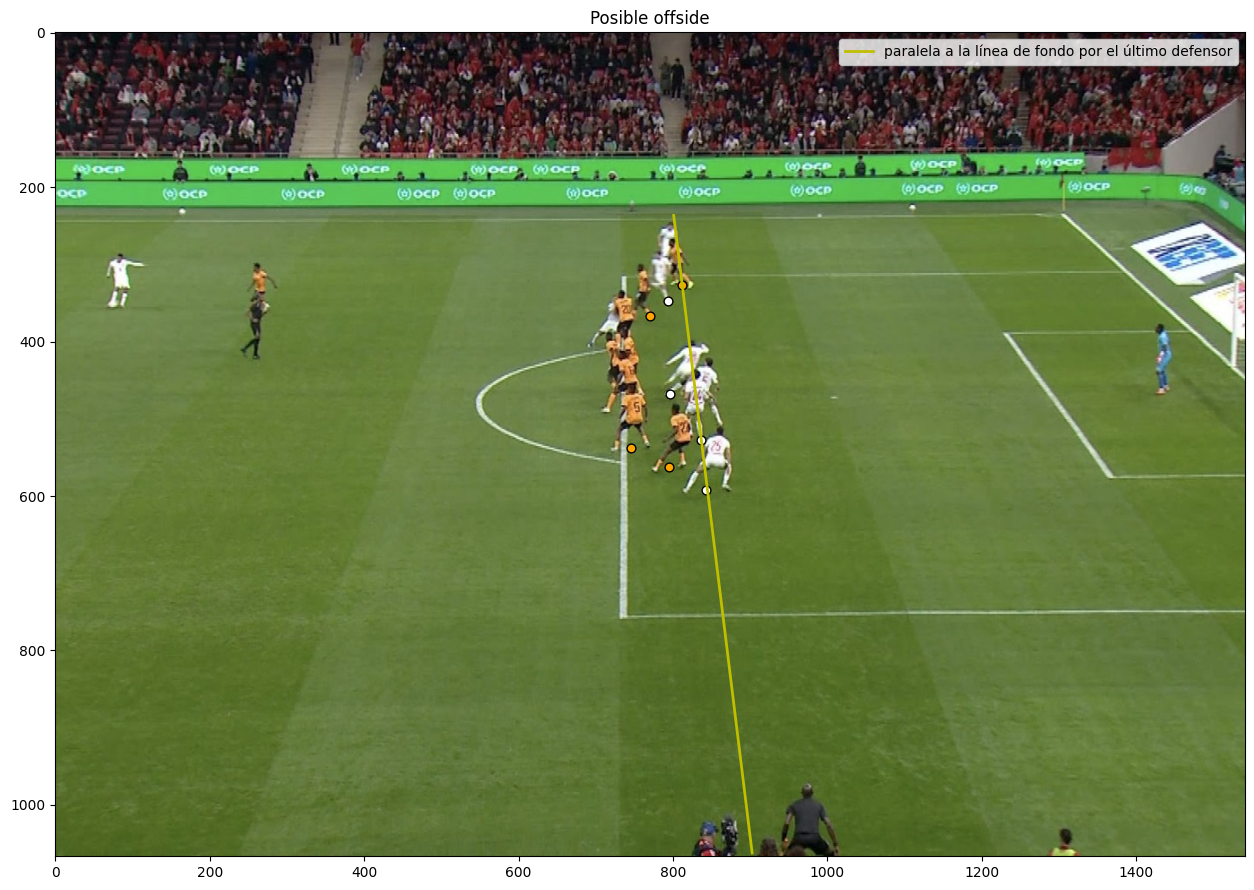

In [ ]:
# Píxel del pie de cada jugador (marcado a mano). Defensores = camiseta naranja; atacantes = camiseta blanca.
defensores = [("def. lejano (arriba)", 812, 327), ("def. (770,367)", 770, 367),
              ("def. n.° 5", 746, 538), ("def. n.° 27", 795, 562)]
atacantes = [("atac. (796,468)", 796, 468), ("atac. (843,592)", 843, 592),
             ("atac. (793,347)", 793, 347), ("atac. n.° 24 centro", 836, 528)]
arquero = ("arquero", 1432, 465)

H_off_inv = inversa(H_off)
def a_cancha(u, v):
    p = aplicar_homografia(H_off_inv, np.array([[float(u), float(v)]]))
    return p[0, 0], p[0, 1]

print("%-22s %8s %8s" % ("jugador", "U (m)", "V (m)"))
ult_def = None
for nombre, u, v in defensores:
    Uj, Vj = a_cancha(u, v)
    print("%-22s %8.2f %8.2f" % (nombre, Uj, Vj))
    if ult_def is None or Uj < ult_def[1]:
        ult_def = (nombre, Uj, u, v)          # el defensor más cercano a la línea de fondo (sin contar al arquero)
Ua, Va = a_cancha(arquero[1], arquero[2])
print("%-22s %8.2f %8.2f   (el arquero está más cerca de la línea: es el último adversario)" % (arquero[0], Ua, Va))
print("\nÚltimo defensor de campo (penúltimo adversario): %s a U = %.2f m" % (ult_def[0], ult_def[1]))

TOL = 0.15      # incertidumbre del clic: ~ +-10 px equivale a unos 15 cm en esta zona
print("\n%-22s %8s %22s" % ("atacante", "U (m)", "ventaja sobre la línea"))
for nombre, u, v in atacantes:
    Uj, Vj = a_cancha(u, v)
    ventaja = ult_def[1] - Uj           # > 0: está más cerca del arco que el defensor
    if ventaja > TOL:
        veredicto = "FUERA DE JUEGO"
    elif ventaja < -TOL:
        veredicto = "habilitado"
    else:
        veredicto = "en línea (no concluyente)"
    print("%-22s %8.2f %+10.2f m  -> %s" % (nombre, Uj, ventaja, veredicto))

# Recta paralela a la línea de fondo (U = const) por el pie del último defensor, proyectada a la foto
recta = recta_vertical(ult_def[1], 68.0, 400)
recta_foto = aplicar_homografia(H_off, recta)
alto, ancho = foto_off.shape[0], foto_off.shape[1]
dentro = []
for i in range(recta_foto.shape[0]):
    if 0 <= recta_foto[i, 0] < ancho and 0 <= recta_foto[i, 1] < alto:
        dentro.append([recta_foto[i, 0], recta_foto[i, 1]])
dentro = np.array(dentro)

fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto_off)
ax.plot(dentro[:, 0], dentro[:, 1], 'y-', linewidth=2, label="paralela a la línea de fondo por el último defensor")
for nombre, u, v in defensores:
    ax.scatter([u], [v], s=40, c='orange', edgecolors='k')
for nombre, u, v in atacantes:
    ax.scatter([u], [v], s=40, c='white', edgecolors='k')
ax.legend()
ax.set_title("Posible offside")
plt.tight_layout()
plt.show()

 **Resultado.** El pie del último defensor se encuentra a $U \approx 14{,}65\text{ m}$ de la línea de fondo (es decir, dentro del área grande, cuyo límite reglamentario está a $16{,}5\text{ m}$).
 m. De los atacantes medidos, dos están claramente habilitados (0,5 a 0,7 m más atrás de la línea) y los otros dos quedan a 1 a 3 cm, una diferencia mucho menor que la incertidumbre de los clics. Con esta foto el resultado es "en línea", no concluyente a favor del fuera de juego. La recta se ve inclinada porque las paralelas del piso convergen en un punto de fuga.



## Conclusiones y límites

* a) Enzo estaba a unos 22,15 m de la línea del arco.
* b) Se dibujaron círculos de 1 m de radio en los 6 argentinos (el sexto con los pies tapados, posición estimada).
* c) El último defensor está en $U\approx14{,}65$ m y la posición de los atacantes no permite concluir fuera de juego.
* `H` solo vale para puntos que están en el piso: se usan los pies, no el cuerpo ni la pelota.
* Son capturas de TV: tienen compresión y posible distorsión de lente que el modelo de cámara no contempla.
* En el reglamento cuenta cualquier parte del cuerpo con la que se pueda marcar (salvo los brazos), no solo los pies; varios pies están tapados; y la posición relevante es la del instante del pase.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

## Calculamos la homografía

Si el piso está en $Z=0$, un punto $(X,Y)$ se ve en el píxel $(u,v)$ así:
$$\lambda\begin{bmatrix}u\\v\\1\end{bmatrix}=H\begin{bmatrix}X\\Y\\1\end{bmatrix},\qquad H=K\,[\mathbf r_1\ \ \mathbf r_2\ \ \mathbf t]\quad(\text{salvo escala}).$$
La $H$ se estima, igual que en el ejercicio 4: armamos la matriz $Q$ de $2n\times9$ y tomamos el autovector de menor autovalor de $Q^TQ$, normalizando los puntos elegidos a mano. Usamos la misma función, `estimar_homografia`.

## a) Usamos el método de Zhang

Con una sola $H$ no alcanza: ahí están mezclados $K$ y la pose. Pero **todas las vistas comparten la misma $K$**, y eso nos da ecuaciones de más.

**La idea.** Sean $\mathbf c_i$ las columnas de $H$. Se cumple $\mathbf c_1=s\,K\mathbf r_1$ y $\mathbf c_2=s\,K\mathbf r_2$. Como $\mathbf r_1,\mathbf r_2$ son ortonormales, y llamando $B=K^{-T}K^{-1}$ (que es simétrica):
$$\mathbf c_1^TB\,\mathbf c_2=0,\qquad \mathbf c_1^TB\,\mathbf c_1-\mathbf c_2^TB\,\mathbf c_2=0 .$$
$B$ tiene 6 entradas distintas, $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})$, y cada producto es lineal en $\mathbf b$: $\mathbf c_i^TB\mathbf c_j=\mathbf v_{ij}^T\mathbf b$.

Cada vista nos da 2 filas de una matriz $A\in\mathbb{R}^{2N\times6}$, y resolvemos $A\mathbf b=0$ igual que en el ejercicio 1b (autovector de menor autovalor de $A^TA$). Después hacemos Cholesky: $B=LL^T\Rightarrow K=(L^T)^{-1}$, y dividimos para que $K_{33}=1$.

 $K$ tiene 5 parámetros (4 si $\gamma=0$) y cada vista da 2 ecuaciones. Entonces $N\ge3$ vistas ($N\ge2$ si $\gamma=0$), y tienen que ser bien distintas entre sí.



In [ ]:
import pandas as pd
# Datos de las 4 vistas: 5 puntos con (X, Y, Z) en metros y su píxel (u_k, v_k) en cada vista k. El archivo va separado por ';'
df = pd.read_csv('recursos_entrega/salguero/world_img_pts.csv', sep=';')

#Controlamos que cada homografía sea confiable antes de usarla en Zhang. Si las H están mal, la K que sale de ellas también.

XY = np.array(df[['X', 'Y']], dtype=float)          # ignoramos Z (aproximación: el cordón está a 0,1 m)
Hlst = []
for k in range(4):
    uv = np.array(df[['u_%d' % k, 'v_%d' % k]], dtype=float)
    H = estimar_homografia(uv, XY)
    Hlst.append(H)
    print("vista %d: error de reproyección de la H = %.1f px" % (k, error_reproyeccion(H, uv, XY)))

vista 0: error de reproyección de la H = 6.2 px
vista 1: error de reproyección de la H = 8.1 px
vista 2: error de reproyección de la H = 6.7 px
vista 3: error de reproyección de la H = 6.6 px


In [ ]:
# Usamos Zhang
A = armarA(Hlst)                                  # 8 x 6 (2 filas por vista)
K_zhang = calcularMatrizK2D(A)
print("A:", A.shape)
print("K con Zhang completo (4 vistas del CSV):\n", K_zhang)

A: (8, 6)
K con Zhang completo (4 vistas del CSV):
 [[2794.4836 1245.5477  326.0348]
 [   0.      228.1974  213.4839]
 [   0.        0.        1.    ]]


Esta $K$ no tiene sentido físico: el skew da ~1300 px y $\alpha_v\approx 200$ px contra $\alpha_u\approx 2800$ px. Pasa porque el problema está mal condicionado: tenemos solo 8 ecuaciones para 5 incógnitas, las vistas se parecen mucho entre sí (misma calle y cámara casi fija). De cada homografía salen apenas 5 puntos, con errores de varios píxeles.

Como Zhang completo no funcionó con estas vistas, usamos un modelo más simple de la cámara: suponemos que no tiene skew, que los píxeles son cuadrados y que el centro óptico está en el medio de la imagen, es decir en (800, 600). Así K depende solo de la focal f, y esa es la única incógnita. Cada homografía nos da dos estimaciones de f: una a partir de que r1 y r2 son perpendiculares, y otra a partir de que tienen la misma norma. Si la homografía es buena, las dos estimaciones dan parecido.

In [ ]:
# Estimación de f con K = [[f,0,800],[0,f,600],[0,0,1]].
datos = np.loadtxt('recursos_entrega/salguero/gs_10_09_point_correspondences_v5.txt')   # 6 filas: índice, X, Y, Z, u, v ; una columna por punto

XY51 = datos[1:3].T                                # (51 x 2) metros
UV51 = datos[4:6].T                                # (51 x 2) píxeles
Z51 = datos[3]
H51 = estimar_homografia(UV51, XY51)
print("H de los 51 puntos: error de reproyección = %.1f px   (todos tienen Z = %s)" % (error_reproyeccion(H51, UV51, XY51), set(Z51)))

est = estimar_focal(Hlst + [H51], 800.0, 600.0)
nombres = ["CSV vista 0", "CSV vista 1", "CSV vista 2", "CSV vista 3", "51 puntos"]
print("%-12s %12s %14s" % ("homografía", "f (orto)", "f (igual norma)"))
for n, (fo, fn) in zip(nombres, est):
    print("%-12s %12.0f %14.0f" % (n, fo, fn))

H de los 51 puntos: error de reproyección = 8.1 px   (todos tienen Z = {np.float64(0.0)})
homografía       f (orto) f (igual norma)
CSV vista 0          1594           3085
CSV vista 1          2595           4114
CSV vista 2          2358           3219
CSV vista 3          2214           3314
51 puntos            1909           2003


Podemos ver que las vistas del CSV dan focales muy desparejas (de ~1600 a ~4100 px) y las dos condiciones no coinciden entre sí: con homografías de 5 puntos no se puede confiar. En cambio, la homografía de los **51 puntos** da dos estimaciones casi iguales (≈1909 y ≈2003 px). Tomamos el promedio, **$f\approx1956$ px**, como valor de trabajo.

In [ ]:
f = (est[4][0] + est[4][1]) / 2.0
K = np.array([[f, 0.0, 800.0],
              [0.0, f, 600.0],
              [0.0, 0.0, 1.0]])
print("K de trabajo:\n", K)

K de trabajo:
 [[1955.7713    0.      800.    ]
 [   0.     1955.7713  600.    ]
 [   0.        0.        1.    ]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [ ]:
R, t = obtenerPose2D_ej5(H51, K)
print("R =\n", R)
print("t =", t)
C = centro_camara(R, t)
print("Centro de la cámara en el mundo (X, Y, Z) = ", C, "  -> altura %.1f m" % C[2])

# Reproyección de los 51 puntos: P = (X, Y, Z) con la M = K [R | t]
puntos3d = np.zeros((51, 3))
puntos3d[:, 0] = XY51[:, 0]; puntos3d[:, 1] = XY51[:, 1]; puntos3d[:, 2] = Z51
M = armar_M(K, R, t)
reproy = proyectar_M_ej5(M, puntos3d)
errores = np.zeros(51)
for i in range(51):
    errores[i] = np.sqrt((reproy[i, 0] - UV51[i, 0]) ** 2 + (reproy[i, 1] - UV51[i, 1]) ** 2)
print("Error de reproyección: RMS = %.2f px, máximo = %.2f px" % (error_reproyeccion_3d_ej5(M, UV51, puntos3d), np.max(errores)))

R =
 [[ 0.9881  0.1539  0.0022]
 [ 0.0343 -0.2059 -0.978 ]
 [-0.1501  0.9664 -0.2088]]
t = [-3.3003 -1.0248 22.5406]
Centro de la cámara en el mundo (X, Y, Z) =  [  6.6783 -21.4861   3.711 ]   -> altura 3.7 m
Error de reproyección: RMS = 7.46 px, máximo = 17.05 px


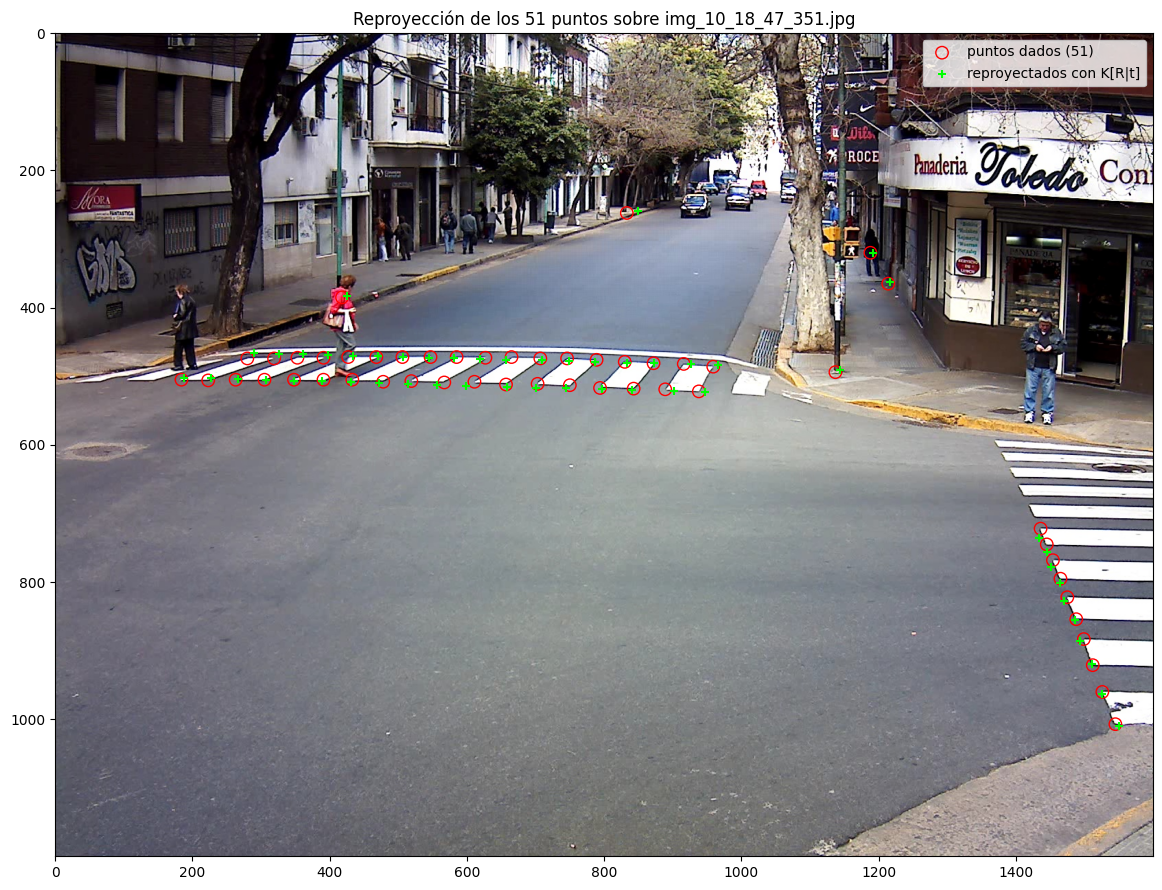

In [ ]:
foto = mpimg.imread('recursos_entrega/salguero/img_10_18_47_351.jpg')
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(foto)
ax.scatter(UV51[:, 0], UV51[:, 1], s=80, facecolors='none', edgecolors='r', label='puntos dados (51)')
ax.scatter(reproy[:, 0], reproy[:, 1], s=35, c='lime', marker='+', label='reproyectados con K[R|t]')
ax.set_title("Reproyección de los 51 puntos sobre img_10_18_47_351.jpg")
ax.legend()
plt.tight_layout()
plt.show()

b) La cámara queda a unos 3,7 m de altura, lo cual tiene sentido para una cámara sobre la calle. El error de reproyección es de unos 7 px (máximo ~17.05 px), parecido al de la propia homografía. Eso hace pensar que viene del ruido en los puntos o de la distorsión del lente (que el modelo pinhole no contempla) y no da un error en la pose. De todos modos, ese error limita la precisión de todo lo que sigue.

## c) Velocidades

 Queremos saber a cuántos km/h van el taxi, la camioneta y la señora. Para eso necesitamos saber **dónde están en metros** en cada instante. Lo que tenemos son fotos, así que hay que pasar de píxeles a metros. Como los tres objetos se mueven **sobre el piso de la calle**, podemos usar la homografía $H$ del inciso b (la de los 51 puntos, que es la misma $H\approx K[\mathbf r_1\ \mathbf r_2\ \mathbf t]$ de la que sacamos la pose). Con su inversa, cada píxel del piso se convierte en metros:
$$(X,Y)=\text{dehomogeneizar}\big(H^{-1}[u\ v\ 1]^T\big)$$
Es decir: multiplicamos $H^{-1}$ por $(u,v,1)$, nos da tres números $(a,b,c)$, y la posición es $X=a/c$, $Y=b/c$. $X$ es a lo ancho de la calle e $Y$ a lo largo.


**Pasos:**
1. La cámara tiene que estar fija durante el video (se puede chequear con algo que no se mueve, como el cartel o el hombre parado en la esquina).
2. En cada captura marcamos el **punto de contacto con el piso** de cada objeto, siempre el **mismo punto**: el centro del borde de abajo del auto (a la altura de las ruedas) y el punto medio entre los dos pies de la señora.
3. La posición en metros sale de $H^{-1}$. El momento de cada captura sale del nombre del archivo.
4. La velocidad entre dos capturas seguidas es $v_k=\|P_{k+1}-P_k\|/(t_{k+1}-t_k)$. Para pasar a km/h multiplicamos por $3{,}6$. Además ajustamos una recta a $X(t)$ y a $Y(t)$ por mínimos cuadrados: su pendiente da una velocidad media más confiable.

**Por qué el punto en el piso:** la homografía solo vale para puntos que están en el plano de la calle. Si marcáramos algo a más altura (la patente, el techo), se proyectaría en otro lugar y el error cambia según dónde esté el auto, así que ensucia la velocidad.

**Cómo se propaga el error.** Un error de $\delta$ píxeles son $\delta/(\text{píxeles por metro})$ metros, y en la velocidad el error es del orden de $\sqrt2\,\sigma_{pos}/\Delta t$. O sea que si los cuadros están muy juntos ($\Delta t$ chico) el ruido se agranda, y los objetos lejanos (pocos píxeles por metro) son los más sensibles.

### Los cuadros del video

La carpeta de Drive tiene 46 cuadros (`img_10_18_47_351.jpg` hasta `img_10_18_52_546.jpg`): el momento de cada captura lo sacamos del nombre del archivo y no suponemos un intervalo fijo. El primero es la imagen del inciso b.

Marcar los 46 cuadros es muy costoso y además, si están muy pegados, las velocidades salen muy ruidosas ($\Delta t$ chico). Usamos 1 de cada 4 (`PASO = 5`): asi tenemos, 10 capturas por objeto, con $\Delta t\approx0{,}55$ s.

In [ ]:
import os

# Los 46 fotogramas del video (carpeta de Drive del enunciado)
gs_dataset = [
    'img_10_18_47_351.jpg',
    'img_10_18_47_461.jpg',
    'img_10_18_47_554.jpg',
    'img_10_18_47_679.jpg',
    'img_10_18_47_835.jpg',
    'img_10_18_47_882.jpg',
    'img_10_18_48_022.jpg',
    'img_10_18_48_163.jpg',
    'img_10_18_48_209.jpg',
    'img_10_18_48_350.jpg',
    'img_10_18_48_475.jpg',
    'img_10_18_48_724.jpg',
    'img_10_18_48_818.jpg',
    'img_10_18_49_005.jpg',
    'img_10_18_49_099.jpg',
    'img_10_18_49_286.jpg',
    'img_10_18_49_317.jpg',
    'img_10_18_49_457.jpg',
    'img_10_18_49_582.jpg',
    'img_10_18_49_660.jpg',
    'img_10_18_49_785.jpg',
    'img_10_18_49_879.jpg',
    'img_10_18_49_988.jpg',
    'img_10_18_50_128.jpg',
    'img_10_18_50_206.jpg',
    'img_10_18_50_300.jpg',
    'img_10_18_50_471.jpg',
    'img_10_18_50_534.jpg',
    'img_10_18_50_674.jpg',
    'img_10_18_50_783.jpg',
    'img_10_18_50_893.jpg',
    'img_10_18_50_986.jpg',
    'img_10_18_51_173.jpg',
    'img_10_18_51_251.jpg',
    'img_10_18_51_345.jpg',
    'img_10_18_51_470.jpg',
    'img_10_18_51_563.jpg',
    'img_10_18_51_657.jpg',
    'img_10_18_51_844.jpg',
    'img_10_18_51_875.jpg',
    'img_10_18_52_000.jpg',
    'img_10_18_52_109.jpg',
    'img_10_18_52_219.jpg',
    'img_10_18_52_312.jpg',
    'img_10_18_52_453.jpg',
    'img_10_18_52_546.jpg'
]
nombres_ordenados = sorted(gs_dataset, key=tiempo_desde_nombre)          # ordenados por instante
instantes = np.zeros(len(nombres_ordenados))
for k in range(len(nombres_ordenados)):
    instantes[k] = tiempo_desde_nombre(nombres_ordenados[k]) - tiempo_desde_nombre(nombres_ordenados[0])
print("%d fotogramas, duración %.2f s, intervalo medio %.3f s" % (len(instantes), instantes[-1], instantes[-1] / (len(instantes) - 1)))

PASO = 5                                                                      # usar 1 de cada PASO fotogramas
nombres_usados = nombres_ordenados[::PASO]
print("Fotogramas a marcar: %d (uno de cada %d)" % (len(nombres_usados), PASO ))

CARPETA_VIDEO = 'salguero/video'                                             # carpeta con los fotogramas bajados de Drive

def ruta_captura(nombre):
    """Arma la ruta de una captura del video.
    Recibe: nombre (str), nombre del archivo, por ejemplo 'img_10_18_47_351.jpg'.
    Devuelve: (str) ruta del archivo dentro de CARPETA_VIDEO."""
    return os.path.join(CARPETA_VIDEO, nombre)

# armamos la lista, ordenamos por hora y elegimos cuáles vamos a marcar

46 fotogramas, duración 5.19 s, intervalo medio 0.115 s
Fotogramas a marcar: 10 (uno de cada 5)


### Puntos de contacto con el piso

Para cada captura de `nombres_usados` marcamos 3 puntos, siempre en este orden: taxi, camioneta, peatona (el punto donde cada uno toca el piso, en píxeles $(u,v)$). Quedan en el diccionario `clics_reales`, con una lista de 10 puntos por objeto, en el orden de `nombres_usados`. La celda que sigue los dibuja sobre tres capturas para ver que cayeron donde tenían que caer.

In [ ]:
# Píxel (u, v) del punto de contacto con el piso de cada objeto, uno por cada captura de nombres_usados (PASO = 5).
# Marcados a mano por el grupo sobre cada captura.
clics_reales = {
    'taxi': [(940, 266), (921, 276), (904, 280), (876, 287), (840, 303), (811, 316), (773, 334), (711, 363), (601, 419), (400, 510)],
    'camioneta': [(994, 252), (993, 251), (993, 264), (984, 273), (964, 280), (958, 287), (947, 302), (925, 320), (879, 358), (820, 396)],
    'peatona': [(425, 500), (488, 500), (553, 493), (632, 492), (697, 492), (749, 491), (802, 492), (853, 491), (940, 487), (999, 485)],
}



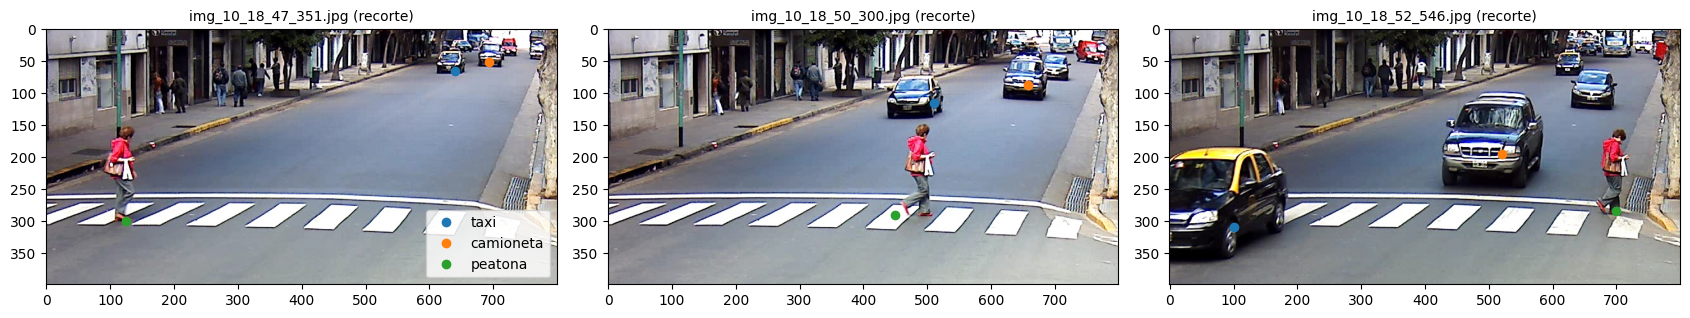

In [ ]:
# Control visual: los puntos tienen que caer sobre el piso, debajo del auto / en los pies de la peatona
ks = [0, len(nombres_usados) // 2, len(nombres_usados) - 1]
u_min, u_max, v_min, v_max = 300, 1100, 200, 600                  # recorte de la zona de la calle donde ocurre todo
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, k in zip(ejes, ks):
    foto = mpimg.imread(ruta_captura(nombres_usados[k]))
    ax.imshow(foto[v_min:v_max, u_min:u_max])
    for objeto in clics_reales:                                   # los píxeles del recorte se corren u_min, v_min
        ax.plot(clics_reales[objeto][k][0] - u_min, clics_reales[objeto][k][1] - v_min, 'o', ms=6, label=objeto)
    ax.set_title(nombres_usados[k] + " (recorte)", fontsize=10)
ejes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# Instante de cada captura usada, en segundos desde la primera
t0 = tiempo_desde_nombre(nombres_usados[0])
tiempos = np.zeros(len(nombres_usados))
for k in range(len(nombres_usados)):
    tiempos[k] = tiempo_desde_nombre(nombres_usados[k]) - t0

# H51 es la homografía calle -> foto del inciso a)/b). pixel_a_metros la invierte y pasa píxeles a metros.
resultados = {}
for objeto in clics_reales:
    pix = np.array(clics_reales[objeto], dtype=float)
    pos = pixel_a_metros(H51, pix)                                  # metros: X a lo ancho de la calle, Y a lo largo
    v = velocidades_consecutivas(tiempos, pos)                      # m/s entre capturas consecutivas
    vx, vy, rapidez = velocidad_por_ajuste(tiempos, pos)            # recta ajustada a X(t) e Y(t)
    resultados[objeto] = (pos, v, vx, vy, rapidez)
    print("%-10s X: %5.1f -> %5.1f m | Y: %5.1f -> %5.1f m | vx = %5.2f m/s, vy = %5.2f m/s | velocidad media = %4.1f km/h"
          % (objeto, pos[0, 0], pos[-1, 0], pos[0, 1], pos[-1, 1], vx, vy, rapidez * 3.6))

taxi       X:  -0.4 ->  -1.3 m | Y:  70.4 ->  -0.1 m | vx = -0.17 m/s, vy = -13.03 m/s | velocidad media = 46.9 km/h
camioneta  X:   1.0 ->   1.8 m | Y:  89.9 ->  13.2 m | vx =  0.16 m/s, vy = -15.11 m/s | velocidad media = 54.4 km/h
peatona    X:  -1.3 ->   5.4 m | Y:   0.6 ->   3.0 m | vx =  1.27 m/s, vy =  0.42 m/s | velocidad media =  4.8 km/h


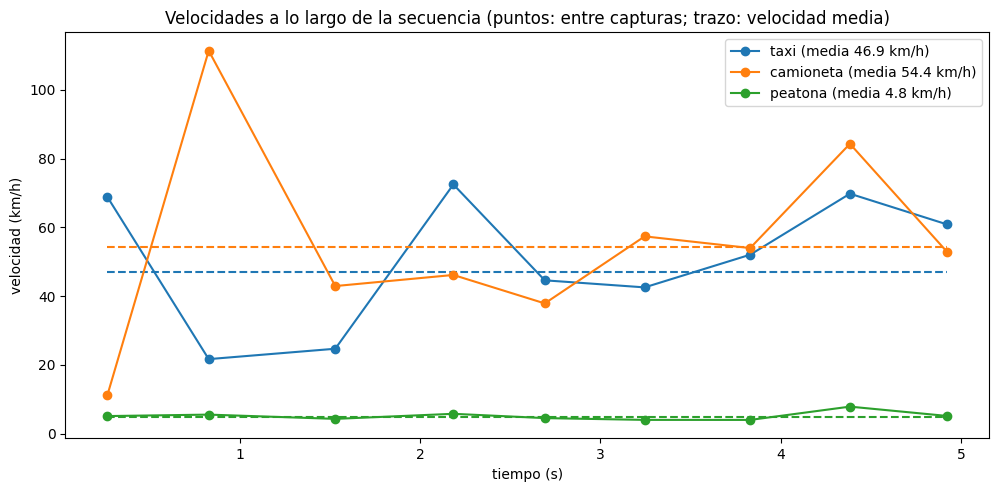

In [ ]:
# Velocidad en función del tiempo (lo que pide la consigna)
colores = {'taxi': 'tab:blue', 'camioneta': 'tab:orange', 'peatona': 'tab:green'}
fig, ax = plt.subplots(figsize=(10, 5))
for objeto in resultados:
    pos, v, vx, vy, rapidez = resultados[objeto]
    t_medio = (tiempos[1:] + tiempos[:-1]) / 2.0                    # cada velocidad corresponde al punto medio del intervalo
    ax.plot(t_medio, v * 3.6, 'o-', color=colores[objeto], label="%s (media %.1f km/h)" % (objeto, rapidez * 3.6))
    ax.plot([t_medio[0], t_medio[-1]], [rapidez * 3.6, rapidez * 3.6], '--', color=colores[objeto])   # velocidad media
ax.set_title("Velocidades a lo largo de la secuencia (puntos: entre capturas; trazo: velocidad media)")
ax.text(0.5, -0.1, "tiempo (s)", transform=ax.transAxes, ha='center')
ax.text(-0.06, 0.5, "velocidad (km/h)", transform=ax.transAxes, rotation=90, va='center')
ax.legend()
plt.tight_layout()
plt.show()

**Qué vemos en**
- Los dos autos se acercan a la cámara ($Y$ baja) con velocidad bastante constante y casi sin irse de costado. La señora cruza por la senda peatonal ($X$ sube) caminando normal (alrededor de 1,4 m/s, unos 5 km/h).
- La velocidad entre capturas seguidas oscila bastante alrededor de la media, sobre todo al principio, cuando los autos están lejos: ahí un píxel son casi 1 m (ver el chequeo 1) y con $\Delta t\approx0{,}55$ s un error de un píxel cambia la velocidad en varios km/h. Por eso damos como resultado la velocidad media por recta ajustada, que usa todas las capturas, y mostramos las velocidades entre capturas para que se vea la dispersión.
- Los chequeos 2 y 3 dan valores parecidos a la media: la velocidad no cambia mucho según la mitad de la secuencia que miremos ni según cuál de las dos homografías usemos. Con los puntos que marcamos, el taxi va a unos 47 km/h, la camioneta a unos 54 km/h y la señora a unos 5 km/h.
- **Incertidumbre:** unos ±5 km/h para los autos (por el error de la homografía, de ≈7 px, y por la distancia) y menos de 1 km/h para la señora, que está cerca de la cámara.

**Limitaciones:** los puntos los marcamos a ojo sobre las capturas (error de unos 2 a 5 píxeles); puede haber distorsión del lente que el modelo pinhole no contempla; $H$ solo vale para el piso; asumimos que la cámara está fija; y los tiempos salen de los nombres de archivo, que tienen intervalos irregulares.